# 02 – Modélisation et prévisions

Prévision des ventes hebdomadaires totales du bonnet de ski (55 magasins) pour les 40 semaines du test
(`week_id` 202335 → 202422). Deux modèles sont testés à chaque étape :

| Étape | Modèle 1 | Modèle 2 |
|---|---|---|
| 2. Baselines | Seasonal naive | Seasonal naive ajusté par `n_stores` |
| 3. Méthodes classiques | ARIMA | SARIMAX |
| 4. Machine learning | Random Forest | XGBoost |
| 5. Deep learning simple | MLP | LSTM |
| 6. Deep learning avancé | TFT | N-HiTS |

Tous les modèles sont évalués sur **le même fold de validation** (voir EDA, section 6) avec la **MSE**,
puis réentraînés sur tout l'historique pour produire une soumission.

## 1. Préparation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

DATA_DIR = Path('../centrale-lille-decathlon-forecast-project-10-2026')
SUB_DIR = Path('../submissions')
SUB_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['date'])
test = pd.read_csv(DATA_DIR / 'test.csv', parse_dates=['date'])
sample_sub = pd.read_csv(DATA_DIR / 'submission.csv')

### 1.1 Série hebdomadaire

Une ligne par semaine avec le total des ventes (`sales`, inconnu sur le test) et le nombre de magasins ayant vendu
(`n_stores`, connu aussi sur le test). Les semaines absentes du train correspondent à 0 vente.

In [2]:
def weekly(df):
    agg = df.groupby('date').agg(n_stores=('bu', 'size'), week_id=('week_id', 'first'))
    if 'sales_quantity' in df:
        agg['sales'] = df.groupby('date').sales_quantity.sum()
    return agg

w_train, w_test = weekly(train), weekly(test)
full_idx = pd.date_range(w_train.index.min(), w_test.index.max(), freq='W-SUN')
w = pd.concat([w_train, w_test]).reindex(full_idx)
w.index.name = 'date'

is_train = w.index <= train.date.max()
w.loc[is_train, ['sales', 'n_stores']] = w.loc[is_train, ['sales', 'n_stores']].fillna(0)
w['n_stores'] = w['n_stores'].fillna(0).astype(int)
# week_id Decathlon = semaine ISO du lendemain (la semaine commence le dimanche)
iso = (w.index + pd.Timedelta(days=1)).isocalendar()
w['week_id'] = (iso.year * 100 + iso.week).values

hist = w[is_train].copy()          # tout l'historique connu
future = w[~is_train].copy()       # 40 semaines à prévoir
assert (future.week_id.values == sample_sub.ID.values).all()
print(f'Historique : {len(hist)} semaines | à prévoir : {len(future)} semaines')
w.tail()

Historique : 102 semaines | à prévoir : 40 semaines


,n_stores,week_id,sales
date,,,
2024-04-28,2,202418,NaN
2024-05-05,3,202419,NaN
2024-05-12,2,202420,NaN
2024-05-19,1,202421,NaN
2024-05-26,2,202422,NaN


### 1.2 Fold de validation

On reproduit la situation du test : entraînement jusqu'au 21/08/2022, prévision des 40 semaines suivantes
(28/08/2022 → 28/05/2023).

In [3]:
VAL_START = pd.Timestamp('2022-08-28')
H = 40
val_train = hist[hist.index < VAL_START]
val_future = hist[hist.index >= VAL_START].iloc[:H]
y_val = val_future.sales
print('Train :', val_train.index[0].date(), '→', val_train.index[-1].date(), f'({len(val_train)} sem.)')
print('Val   :', val_future.index[0].date(), '→', val_future.index[-1].date(), f'({len(val_future)} sem.)')

Train : 2021-09-12 → 2022-08-21 (50 sem.)
Val   : 2022-08-28 → 2023-05-28 (40 sem.)


### 1.3 Fonctions communes

Chaque modèle est une fonction `forecast(past, fut)` :
- `past` : historique (colonnes `sales`, `n_stores`, `week_id`)
- `fut` : semaines à prévoir (`n_stores`, `week_id` ; pas de `sales`)
- renvoie une `pd.Series` de prévisions indexée comme `fut`

La même fonction sert pour la validation et pour la soumission finale.

In [4]:
results = {}       # métriques de validation par modèle
val_preds = {}     # prévisions de validation par modèle

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    return {'MSE': np.mean(err ** 2), 'RMSE': np.sqrt(np.mean(err ** 2)),
            'MAE': np.mean(np.abs(err)), 'WAPE': np.abs(err).sum() / np.abs(y_true).sum()}

def evaluate(name, forecast):
    """Entraîne sur le fold, prévoit les 40 semaines de validation, enregistre et affiche les métriques."""
    pred = forecast(val_train, val_future.drop(columns='sales')).clip(lower=0)
    val_preds[name] = pred
    results[name] = metrics(y_val, pred)
    print(name, '|', ' | '.join(f'{k} = {v:,.3f}' if k == 'WAPE' else f'{k} = {v:,.0f}' for k, v in results[name].items()))
    return pred

def plot_val(names, title='Validation: forecast vs actual'):
    fig, ax = plt.subplots()
    ax.plot(y_val.index, y_val, color='k', lw=2, label='Actual')
    for n in names:
        ax.plot(val_preds[n].index, val_preds[n], marker='.', label=n)
    ax.set_title(title); ax.set_ylabel('units sold'); ax.legend(); plt.show()

def make_submission(name, forecast):
    """Réentraîne sur tout l'historique, prévoit le test et écrit le fichier de soumission."""
    pred = forecast(hist, future.drop(columns='sales')).clip(lower=0)
    sub = pd.DataFrame({'ID': future.week_id.values, 'TARGET': pred.values})
    path = SUB_DIR / f'{name}.csv'
    sub.to_csv(path, index=False)
    print(f'Soumission écrite : {path} ({len(sub)} lignes, total prévu = {sub.TARGET.sum():,.0f})')
    return pred

def results_table():
    return pd.DataFrame(results).T.sort_values('MSE').style.format(
        {'MSE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAE': '{:,.0f}', 'WAPE': '{:.1%}'})

## 2. Baselines

Modèles très simples, sans apprentissage, qui servent de référence : un modèle plus complexe n'est utile
que s'il fait mieux qu'eux.

### 2.1 Seasonal naive

Prévision = ventes de **la même semaine l'année précédente** (52 semaines plus tôt) :

$$\hat{y}_t = y_{t-52}$$

Si la semaine t−52 est antérieure au début des données, la prévision vaut 0 (période creuse).

In [5]:
def seasonal_naive(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    return pd.Series(past.sales.reindex(lag).fillna(0).values, index=fut.index)

evaluate('Seasonal naive', seasonal_naive);

Seasonal naive | MSE = 409,124 | RMSE = 640 | MAE = 392 | WAPE = 0.428


### 2.2 Seasonal naive ajusté par `n_stores`

On sait combien de magasins vendront chaque semaine du test. On garde les **ventes moyennes par magasin actif**
de l'année précédente et on les multiplie par le nombre de magasins actifs de la semaine à prévoir :

$$\hat{y}_t = n\_stores_t \times \frac{y_{t-52}}{n\_stores_{t-52}}$$

Ainsi, si la saison démarre plus tôt ou plus tard que l'année précédente, la prévision suit.

In [6]:
def seasonal_naive_stores(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    per_store = (past.sales / past.n_stores.replace(0, np.nan)).reindex(lag).fillna(0)
    return pd.Series(fut.n_stores.values * per_store.values, index=fut.index)

evaluate('Seasonal naive × n_stores', seasonal_naive_stores);

Seasonal naive × n_stores | MSE = 416,524 | RMSE = 645 | MAE = 395 | WAPE = 0.432


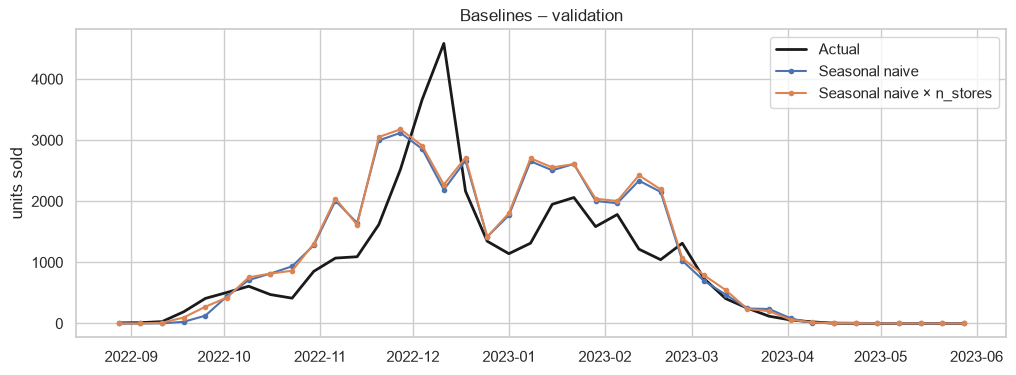

,MSE,RMSE,MAE,WAPE
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%


In [7]:
plot_val(['Seasonal naive', 'Seasonal naive × n_stores'], 'Baselines – validation')
results_table()

### 2.3 Analyse des baselines

- Les deux baselines obtiennent des scores quasi identiques (MSE ≈ 409 000 contre ≈ 417 000, WAPE ≈ 43 %).
- **L'ajustement par `n_stores` n'apporte rien** : en pleine saison, `n_stores` vaut ≈ 55 les deux années, donc le ratio est ≈ 1.
  Il n'agit qu'en début et fin de saison, où les volumes sont faibles et pèsent peu dans la MSE.
- **L'erreur vient surtout du pic** : en 2021-22 le pic a eu lieu fin novembre, en 2022-23 à la mi-décembre, plus haut (≈ 4 600).
  Copier l'année précédente décale le pic et sous-estime son niveau, puis surestime janvier–février (saison 2022-23 plus faible de 17 %).
- Pour la soumission, le seasonal naive copie la saison 2022-23, y compris son pic exceptionnel de décembre.
- Pistes pour les modèles suivants : utiliser les **deux saisons** disponibles (moyenne), aligner sur le **calendrier**
  (Black Friday, semaines avant Noël) plutôt que sur un décalage fixe de 52 semaines.

In [8]:
for name, fn in [('baseline_seasonal_naive', seasonal_naive),
                 ('baseline_seasonal_naive_stores', seasonal_naive_stores)]:
    make_submission(name, fn)

Soumission écrite : ..\submissions\baseline_seasonal_naive.csv (40 lignes, total prévu = 36,582)
Soumission écrite : ..\submissions\baseline_seasonal_naive_stores.csv (40 lignes, total prévu = 36,501)


## 3. Méthodes classiques

Modèles statistiques sur le log des ventes (`log1p`), avec d = 1 d'après l'EDA.

### 3.1 ARIMA

ARIMA sur `log1p(sales)` ; ordre choisi via ACF/PACF (point de départ ARIMA(1,1,0)) ou `auto_arima`.

In [9]:
# TODO

### 3.2 SARIMAX

SARIMAX avec `n_stores` (et éventuellement des indicatrices de calendrier) comme variables exogènes.

In [10]:
# TODO

## 4. Machine learning

Modèles à base d'arbres sur des features : calendrier (semaine de la saison, Black Friday, Noël), `n_stores`, ventes de la même semaine l'année précédente.

### 4.1 Random Forest

In [11]:
# TODO

### 4.2 XGBoost

In [12]:
# TODO

## 5. Deep learning simple

Réseaux de neurones simples, entraînés sur les mêmes features ou sur des fenêtres de la série.

### 5.1 MLP

Perceptron multicouche sur les features de l'étape 4.

In [13]:
# TODO

### 5.2 LSTM

Réseau récurrent sur des séquences de semaines.

In [14]:
# TODO

## 6. Deep learning avancé

Architectures récentes présentées par Decathlon (TFT, N-HiTS).

### 6.1 TFT (Temporal Fusion Transformer)

In [15]:
# TODO

### 6.2 N-HiTS

In [16]:
# TODO

## 7. Comparaison des modèles et soumission finale

In [17]:
results_table()

,MSE,RMSE,MAE,WAPE
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%


*À compléter : choix du modèle final (ou ensemble) et justification.*